# K-Means on CPU: optimised baseline for the CPU vs GPU comparison

This notebook re-runs the CPU K-means experiments with an optimised, multi-threaded implementation of **Lloyd's algorithm**.
Its outputs use the same format as the original runs (`initial_centroids_*.csv`, `final_results_*.csv`), so they can be compared directly with your existing CPU results and with the GPU runs. It also writes `assignments/assignments_*.csv`, which gives the cluster for every ID.

**What changed compared with the original runs**

| Area | Original runs | This notebook |
| --- | --- | --- |
| Distance + assignment | Probably NumPy broadcasting with an n × K × d temporary array (inferred from the timings) | Fused, parallel Numba kernel: one pass over the data, no temporaries, all cores |
| Centroid update | Unknown (often a Python loop with one boolean mask per cluster) | Accumulated inside the same pass; sums kept in float64 |
| K | 17 in every run | The cluster count in the file name (`..._3_clusters` means K = 3) |
| Features | 9 values per centroid up to 100k rows, but 10 at 1M rows or more (the 10th is a whole number 0 to k−1, source unknown) | The 9 feature columns at every size; the ID column is kept aside, not clustered |
| Per-ID output | None | `ID, cluster, distance` for every row, against the final centroids |
| Initial centroids | Saved per run | The **same** saved centroids are reused (label column sliced off), so results stay comparable |
| Main metric | Total time (depends on iteration count) | **Median time per iteration** over fixed-iteration runs, plus a separate run to convergence |
| Repeats / warm-up | 1 run, no warm-up | 1 warm-up run, then 5 timed repeats |
| Run record | Not stored | CPU model, thread count and library versions saved to `environment.json` |

The algorithm is unchanged (Lloyd's algorithm, float32 data), so any speedup comes from the implementation, not from a different method.

**How to use it:** set `DATA_DIR` to the folder that contains `rows10000/`, `rows50000/`, ... (data files are found in any subfolder below those) and `ORIGINAL_RESULTS_DIR` in the next cell, run all cells, then send `results_cpu_optimized/summary.csv` and the plot.

## 1. Configuration

In [ ]:
import os
from pathlib import Path
import numpy as np

DATA_DIR = Path("/Users/naginilandarhi/DSAICourse/Prof_Shankar_Venkatagiri/LinAlg4DataScience/faker_data_synthesizer ")                # parent folder that holds rows10000/, rows50000/, ... (absolute paths are fine)
SUBFOLDER_PATTERN = "rows*"         # data subfolders under DATA_DIR, searched recursively; None = search all of DATA_DIR
FILE_PATTERN = "synthetic_data_*_rows_*_cols_*_clusters.csv"
ORIGINAL_RESULTS_DIR = Path("results_onlystats")  # earlier CPU run (initial centroids + timings), searched recursively; None to skip
OUT_DIR = Path("results_cpu_optimized")

SIZES = None              # e.g. [10_000, 1_000_000] to run only some sizes; None = every file found

# K: "generated" uses the cluster count in the file name (..._10_cols_3_clusters -> K = 3). This is the intended setup.
#    "fixed" uses K_FIXED for every file (what the original runs did: 17 everywhere); only for reproducing those runs.
K_MODE = "generated"
K_FIXED = 17

# Columns: text columns (e.g. a hex ID) and row-index columns are always skipped.
# The label (generated cluster id) is excluded from the features. "auto" = a column named label/cluster/target/class/y,
# else the last numeric column if it holds whole numbers. Or give its name (files with a header) or 0-based position
# counted over all columns in the file. None = the files have no label column.
LABEL_COLUMN = "auto"

# ID column: kept out of the features, and used to write each row's centroid.
# "auto" = a column named ID/id/index, else the only text column. Or give its name; None = no ID column (row numbers used).
ID_COLUMN = "auto"
SAVE_ASSIGNMENTS = True        # write assignments/assignments_<file>.csv: ID, cluster, distance to centroid
ASSIGNMENT_COORDS = False      # also write the centroid's coordinates on every row (large files at 10M rows)

# Stopping rule: stop when the largest centroid movement (L2 distance) is below TOL, or at MAX_ITER.
# Set TOL to the value your original code used, and use the SAME value in the GPU code.
TOL = 1e-4
MAX_ITER = 1000

# Timing protocol
BENCH_ITERS = 20          # minimum iterations per timed run (convergence switched off)
BENCH_MIN_SECONDS = 0.5   # each timed run lasts at least this long: small datasets get more iterations,
                          # so thread start-up and timer noise do not dominate their per-iteration time
BENCH_MAX_ITERS = 20_000
BENCH_REPEATS = 5         # timed runs; the median is reported
WARMUP_RUNS = 1           # untimed runs first (also triggers Numba compilation)

# Implementations to time. The first one is also used for the run to convergence.
#   "numba" : parallel fused kernel (recommended optimised baseline)
#   "numpy" : matrix-multiply distances + bincount update (no Numba needed; mostly single-threaded)
#   "naive" : NumPy broadcasting, similar to a typical first implementation (slow, big memory; capped below)
BENCH_IMPLS = ["numba", "numpy"]
NAIVE_MAX_ROWS = 1_000_000

N_THREADS = os.cpu_count()  # threads for Numba and BLAS; record this in the report
SEED = 0                    # only used if no saved initial centroids exist for a file
DTYPE = np.float32

## 2. Environment (saved with the results)

In [ ]:
import json, platform, re, subprocess, sys, time, warnings
import pandas as pd
import numba
from numba import njit, prange
from threadpoolctl import threadpool_info, threadpool_limits

numba.set_num_threads(min(N_THREADS, numba.config.NUMBA_NUM_THREADS))
OUT_DIR.mkdir(parents=True, exist_ok=True)

def cpu_model():
    try:
        if sys.platform == "darwin":
            return subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"], text=True).strip()
        if sys.platform.startswith("linux"):
            for line in open("/proc/cpuinfo"):
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
        return platform.processor() or "unknown"
    except Exception:
        return "unknown"

def total_ram_gb():
    try:
        import psutil
        return round(psutil.virtual_memory().total / 1e9, 1)
    except Exception:
        return None

ENV = {
    "cpu_model": cpu_model(),
    "logical_cores": os.cpu_count(),
    "threads_used": numba.get_num_threads(),
    "ram_gb": total_ram_gb(),
    "platform": platform.platform(),
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "numba": numba.__version__,
    "pandas": pd.__version__,
    "blas": [{k: d.get(k) for k in ("internal_api", "version", "num_threads")} for d in threadpool_info()],
    "config": {"K_MODE": K_MODE, "K_FIXED": K_FIXED, "TOL": TOL, "MAX_ITER": MAX_ITER,
               "BENCH_ITERS": BENCH_ITERS, "BENCH_MIN_SECONDS": BENCH_MIN_SECONDS, "BENCH_REPEATS": BENCH_REPEATS, "LABEL_COLUMN": LABEL_COLUMN, "ID_COLUMN": ID_COLUMN,
               "dtype": np.dtype(DTYPE).name},
}
with open(OUT_DIR / "environment.json", "w") as fh:
    json.dump(ENV, fh, indent=2)
ENV

{'cpu_model': 'Apple M4 Pro',
 'logical_cores': 14,
 'threads_used': 14,
 'ram_gb': 25.8,
 'platform': 'macOS-27.0.1-arm64-arm-64bit',
 'python': '3.12.7',
 'numpy': '1.26.4',
 'numba': '0.60.0',
 'pandas': '2.2.2',
 'blas': [{'internal_api': 'openblas',
   'version': '0.3.23.dev',
   'num_threads': 14},
  {'internal_api': 'openblas', 'version': '0.3.21', 'num_threads': 14}],
 'config': {'K_MODE': 'generated',
  'K_FIXED': 17,
  'TOL': 0.0001,
  'MAX_ITER': 1000,
  'BENCH_ITERS': 20,
  'BENCH_MIN_SECONDS': 0.5,
  'BENCH_REPEATS': 5,
  'LABEL_COLUMN': 'auto',
  'ID_COLUMN': 'auto',
  'dtype': 'float32'}}

## 3. Data loading and initial centroids

The saved initial centroids from the original run are reused, so CPU and GPU start from the same point.
Those files hold 17 randomly sampled points. With `K_MODE = "generated"` the first K of them are used, which is still a random sample of K data points.
For runs of 1M rows or more the original files have 10 values per centroid (label included); the label value is sliced off.
The centroids used are always written to `OUT_DIR`. **Point the GPU code at those files.**

In [ ]:
NAME_RE = re.compile(r"synthetic_data_(\d+)_rows_(\d+)_cols_(\d+)_clusters")

def parse_name(path):
    m = NAME_RE.search(Path(path).name)
    if not m:
        raise ValueError(f"Unexpected file name: {path}")
    n, cols, k = map(int, m.groups())
    return {"rows": n, "cols": cols, "gen_clusters": k, "tag": m.group(0)}

def _inside_out_dir(p):
    try:
        return OUT_DIR.resolve() in Path(p).resolve().parents
    except Exception:
        return False

def find_data_files():
    """Data files in DATA_DIR/<SUBFOLDER_PATTERN>/** (any depth), one per file name."""
    base = Path(DATA_DIR)
    roots = [d for d in sorted(base.glob(SUBFOLDER_PATTERN)) if d.is_dir()] if SUBFOLDER_PATTERN else [base]
    if not roots:
        raise FileNotFoundError(f"No folders matching {SUBFOLDER_PATTERN!r} in {base.resolve()}")
    found = {}
    for root in roots:
        for p in sorted(root.rglob(FILE_PATTERN)):
            if _inside_out_dir(p):
                continue
            if p.name in found:
                warnings.warn(f"Duplicate {p.name}: using {found[p.name]}, ignoring {p}")
                continue
            found[p.name] = p
    for p in found.values():                     # folder rows<N> should match <N>_rows in the file name
        for part in p.relative_to(base).parts[:-1]:
            m = re.fullmatch(r"rows_?(\d+)", part)
            if m and int(m.group(1)) != parse_name(p)["rows"]:
                warnings.warn(f"{p}: folder {part} does not match the row count in the file name")
    return sorted(found.values(), key=lambda p: (parse_name(p)["rows"], parse_name(p)["gen_clusters"]))

def _index_initial_centroids():
    index = {}
    if ORIGINAL_RESULTS_DIR is not None and Path(ORIGINAL_RESULTS_DIR).exists():
        for p in sorted(Path(ORIGINAL_RESULTS_DIR).rglob("initial_centroids_*.csv")):
            if not _inside_out_dir(p):
                index.setdefault(p.name, p)
    return index

LABEL_NAMES = {"label", "labels", "cluster", "clusters", "cluster_id", "target", "class", "y"}
INDEX_NAMES = {"id", "index", "idx", "row", "row_id"}

def _is_number(tok):
    try:
        float(tok)
        return True
    except ValueError:
        return False

def _detect_header(path):
    """Header = some field in line 1 is text where line 2 has a number (an ID column is text on both lines)."""
    with open(path) as fh:
        l1 = fh.readline().strip().split(",")
        l2 = fh.readline().strip().split(",")
    return 0 if any(not _is_number(a) and _is_number(b) for a, b in zip(l1, l2)) else None

def _looks_like_index(col, values):
    name = str(col).strip().lower()
    if name in INDEX_NAMES or name.startswith("unnamed"):
        return True
    v = values.to_numpy()
    return len(v) > 1 and np.array_equal(v, np.arange(v[0], v[0] + len(v)))

def _read_csv(path, header, **kw):
    # index_col=False: if every row ends with a trailing comma, pandas would otherwise
    # turn the first column into the index and shift all column names by one.
    return pd.read_csv(path, header=header, index_col=False, **kw)

def load_dataset(path, meta):
    """Returns (X float32 features, labels or None, layout).

    The ID column is recorded in `layout` (not loaded here) so assignments can be written per ID later.
    Other text columns, row-index columns and empty columns are skipped.
    """
    header = _detect_header(path)
    sniff = _read_csv(path, header, nrows=2000)
    empty = [c for c in sniff.columns if sniff[c].isna().all()]          # e.g. from trailing commas
    cols = [c for c in sniff.columns if c not in empty]
    as_num = {c: pd.to_numeric(sniff[c], errors="coerce") for c in cols}
    numeric = [c for c in cols if as_num[c].notna().all()]
    text = [c for c in cols if c not in numeric]

    if ID_COLUMN == "auto":
        named = [c for c in cols if str(c).strip().lower() in INDEX_NAMES]
        id_col = named[0] if named else (text[0] if len(text) == 1 else None)
    else:
        id_col = ID_COLUMN if ID_COLUMN is None or ID_COLUMN in cols else None
        if ID_COLUMN is not None and id_col is None:
            raise ValueError(f"{Path(path).name}: ID column {ID_COLUMN!r} not found in {cols}")
    numeric = [c for c in numeric if c != id_col]
    index_cols = [c for c in numeric if _looks_like_index(c, as_num[c])]
    numeric = [c for c in numeric if c not in index_cols]
    skipped = [c for c in text if c != id_col] + index_cols + empty

    label = None
    if LABEL_COLUMN == "auto":
        named = [c for c in numeric if str(c).strip().lower() in LABEL_NAMES]
        if named:
            label = named[0]
        elif numeric and (as_num[numeric[-1]] == as_num[numeric[-1]].round()).all():
            label = numeric[-1]
    elif LABEL_COLUMN is not None:
        label = LABEL_COLUMN
        if label not in numeric:
            raise ValueError(f"{Path(path).name}: label column {LABEL_COLUMN!r} not found among numeric columns {numeric}")
    features = [c for c in numeric if c != label]
    if not features:
        raise ValueError(f"{Path(path).name}: no numeric feature columns found")

    usecols = features + ([label] if label is not None else [])
    df = _read_csv(path, header, usecols=usecols, dtype={c: DTYPE for c in features})
    X = np.ascontiguousarray(df[features].to_numpy(dtype=DTYPE))
    y = df[label].to_numpy() if label is not None else None
    layout = {"header": header is not None, "id_column": id_col, "feature_columns": features,
              "label_column": label, "skipped": skipped}
    n_cols = len(features) + (label is not None) + (id_col is not None)
    if n_cols != meta["cols"]:
        warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "
                      f"but the file name says {meta['cols']}. Check the layout: {layout}")
    return X, y, layout

def read_ids(path, layout, n):
    """IDs in file order (row numbers if the file has no ID column)."""
    if layout["id_column"] is None:
        return pd.Series(np.arange(n), name="row")
    header = 0 if layout["header"] else None
    ids = _read_csv(path, header, usecols=[layout["id_column"]], dtype={layout["id_column"]: str})[layout["id_column"]]
    if len(ids) != n:
        raise ValueError(f"{Path(path).name}: {len(ids)} IDs but {n} feature rows")
    return ids.rename("ID")

def choose_k(meta):
    return K_FIXED if K_MODE == "fixed" else meta["gen_clusters"]

def initial_centroids(meta, X, K, data_path):
    """Saved centroids, looked for in: original results (any subfolder), the data file's folder, OUT_DIR."""
    n_features = X.shape[1]
    name = f"initial_centroids_{meta['tag']}.csv"
    candidates = [_index_initial_centroids().get(name), Path(data_path).parent / name, OUT_DIR / name]
    source = None
    for f in candidates:
        if f is None or not Path(f).exists():
            continue
        C = np.loadtxt(f, delimiter=",", ndmin=2)
        if C.shape[1] == n_features + 1:          # original >=1M runs stored the label too
            C = C[:, :n_features]
        if C.shape[1] == n_features and C.shape[0] >= K:
            C, source = C[:K], str(f)
            break
    if source is None:
        rng = np.random.default_rng(SEED)
        C = X[rng.choice(X.shape[0], K, replace=False)]
        source = f"sampled (seed {SEED})"
    C = np.ascontiguousarray(C, dtype=DTYPE)
    np.savetxt(OUT_DIR / name, C, delimiter=",")
    return C, source

**Check the column layout before running everything.** The cell below reads the first data file and shows which column is the ID, which columns are features, and whether any label column was found. For files laid out as `ID,col_1,...,col_9` you should see `id_column: 'ID'`, the 9 `col_*` columns as features, and `label_column: None`. If not, set `ID_COLUMN` / `LABEL_COLUMN` in the configuration cell. Run it on one of the 1M+ files too (set `SIZES`): the original runs had 10 values per centroid at those sizes, so check that those files have the same 9 features.

In [ ]:
_files = find_data_files()
print(f"{len(_files)} data files found")
if _files:
    _p = _files[0]
    with open(_p) as fh:
        print("First lines of", _p)
        for _ in range(3):
            print("   ", fh.readline().rstrip()[:160])
    _X, _y, _layout = load_dataset(_p, parse_name(_p))
    print("layout:", _layout)
    print("X:", _X.shape, _X.dtype, "| label values:", None if _y is None else np.unique(_y)[:20])
    del _X, _y

18 data files found
First lines of /Users/naginilandarhi/DSAICourse/Prof_Shankar_Venkatagiri/LinAlg4DataScience/faker_data_synthesizer/rows10000/synthetic_data_10000_rows_10_cols_3_clusters.csv
    ID,col_1,col_2,col_3,col_4,col_5,col_6,col_7,col_8,col_9
    1ff49b7889464e85b59cde66bacfb3d0,605.1678930313433000,-72.7948777395398300,199.2009351388837000,144.4019795869520200,707.3825495471236000,641.8478315591225000,8
    3b982ef8daf64a26946d3f31fc377a4c,-65.4610673758915700,146.1404302410297500,449.6139537595886400,-86.4679606599989800,123.4404407840184300,619.0897554858645000,5
layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': None, 'skipped': []}
X: (10000, 9) float32 | label values: None


## 4. Implementations

All three implement the same Lloyd iteration:

1. assign every point to its nearest centroid (squared Euclidean distance),
2. move each centroid to the mean of its points (an empty cluster keeps its old position),
3. stop when the largest centroid movement is below `tol`, or after `max_iter` iterations.

Each returns `(centroids, labels, iterations, max_movement)`. `tol < 0` switches convergence off, which the timing runs use.

In [ ]:
@njit(parallel=True, fastmath=True)
def _lloyd_step(X, C, labels, n_blocks):
    """One pass over the data: nearest-centroid assignment + per-block partial sums (float64)."""
    n, d = X.shape
    K = C.shape[0]
    sums = np.zeros((n_blocks, K, d), dtype=np.float64)
    counts = np.zeros((n_blocks, K), dtype=np.int64)
    block = (n + n_blocks - 1) // n_blocks
    for b in prange(n_blocks):
        start = b * block
        end = min(n, start + block)
        for i in range(start, end):
            best_k = 0
            best_d = np.inf
            for k in range(K):
                dist = np.float32(0.0)
                for j in range(d):
                    diff = X[i, j] - C[k, j]
                    dist += diff * diff
                if dist < best_d:
                    best_d = dist
                    best_k = k
            labels[i] = best_k
            counts[b, best_k] += 1
            for j in range(d):
                sums[b, best_k, j] += X[i, j]
    return sums.sum(axis=0), counts.sum(axis=0)


def _update(C, sums, counts):
    newC = C.astype(np.float64)
    nz = counts > 0
    newC[nz] = sums[nz] / counts[nz, None]
    shift = float(np.sqrt(((newC - C) ** 2).sum(axis=1)).max())
    return newC.astype(C.dtype), shift


def kmeans_numba(X, C0, max_iter=MAX_ITER, tol=TOL):
    C = np.array(C0, dtype=X.dtype, copy=True)
    labels = np.empty(X.shape[0], dtype=np.int32)
    n_blocks = max(1, numba.get_num_threads() * 4)
    shift, it = np.inf, 0
    for it in range(1, max_iter + 1):
        sums, counts = _lloyd_step(X, C, labels, n_blocks)
        C, shift = _update(C, sums, counts)
        if shift < tol:
            break
    return C, labels, it, shift


def kmeans_numpy(X, C0, max_iter=MAX_ITER, tol=TOL, chunk=262_144):
    """Matrix-multiply distances (||c||^2 - 2 x.c), bincount update.

    The matrix multiply runs in float64: in float32 the subtraction cancels badly at this data scale
    (values up to ~1000) and flips near-tie assignments, so results drift from the exact clustering.
    """
    mu = X.mean(axis=0, dtype=np.float64).astype(X.dtype)
    Xc = X - mu                                # centring keeps the products small
    C = np.array(C0, dtype=X.dtype, copy=True) - mu
    n, d = X.shape
    K = C.shape[0]
    labels = np.empty(n, dtype=np.int64)
    shift, it = np.inf, 0
    for it in range(1, max_iter + 1):
        C64 = C.astype(np.float64)
        c_sq = (C64 * C64).sum(axis=1)
        for s in range(0, n, chunk):          # ||x||^2 is the same for every centroid, so it is left out
            D = Xc[s:s + chunk].astype(np.float64) @ C64.T
            D *= -2
            D += c_sq
            labels[s:s + chunk] = D.argmin(axis=1)
        counts = np.bincount(labels, minlength=K)
        sums = np.empty((K, d), dtype=np.float64)
        for j in range(d):
            sums[:, j] = np.bincount(labels, weights=Xc[:, j], minlength=K)
        C, shift = _update(C, sums, counts)
        if shift < tol:
            break
    return C + mu, labels, it, shift


def kmeans_naive(X, C0, max_iter=MAX_ITER, tol=TOL):
    """Broadcasting version, similar to a typical first implementation. Reference/comparison only."""
    C = np.array(C0, dtype=X.dtype, copy=True)
    K = C.shape[0]
    shift, it = np.inf, 0
    for it in range(1, max_iter + 1):
        D = ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)
        labels = D.argmin(axis=1)
        newC = C.copy()
        for k in range(K):
            mask = labels == k
            if mask.any():
                newC[k] = X[mask].mean(axis=0)
        shift = float(np.sqrt(((newC.astype(np.float64) - C) ** 2).sum(axis=1)).max())
        C = newC
        if shift < tol:
            break
    return C, labels, it, shift


IMPLS = {"numba": kmeans_numba, "numpy": kmeans_numpy, "naive": kmeans_naive}


@njit(parallel=True, fastmath=True)
def _assign(X, C, labels, dists):
    n, d = X.shape
    K = C.shape[0]
    for i in prange(n):
        best_k = 0
        best_d = np.inf
        for k in range(K):
            dist = 0.0
            for j in range(d):
                diff = np.float64(X[i, j]) - np.float64(C[k, j])
                dist += diff * diff
            if dist < best_d:
                best_d = dist
                best_k = k
        labels[i] = best_k
        dists[i] = np.sqrt(best_d)


def assign_to_centroids(X, C):
    """Nearest final centroid and its Euclidean distance for every row (float64 distances)."""
    labels = np.empty(X.shape[0], dtype=np.int32)
    dists = np.empty(X.shape[0], dtype=np.float64)
    _assign(X, np.ascontiguousarray(C, dtype=X.dtype), labels, dists)
    return labels, dists

## 5. Correctness check

Before timing anything, all implementations are checked against a float64 reference on a small synthetic dataset.
They start from the same centroids and run the same 30 iterations.
A faster implementation only counts as a baseline if it produces the same clustering, so `numba` and `numpy` must pass.

`naive` is reported but not required to pass. With K = 17 there are many near-ties between centroids, so float32 rounding in its distance and mean calculations can flip a few assignments. Those flips then compound from one iteration to the next. **The same applies to the GPU code:** float32 data is fine, but accumulate centroid sums in float64 (or check the GPU against this table) before comparing final centroids.

In [ ]:
def correctness_check(n=20_000, d=9, true_k=7, K=17, iters=30):
    rng = np.random.default_rng(1)
    centers = rng.uniform(-100, 1000, (true_k, d))
    X = (centers[rng.integers(0, true_k, n)] + rng.normal(0, 15, (n, d))).astype(DTYPE)
    C0 = X[rng.choice(n, K, replace=False)].copy()
    C_ref, lab_ref, _, _ = kmeans_naive(X.astype(np.float64), C0.astype(np.float64), iters, -1.0)
    rows = []
    for name, fn in IMPLS.items():
        C, lab, it, _ = fn(X, C0, iters, -1.0)
        rows.append({"implementation": name, "iterations": it,
                     "max |centroid - reference|": float(np.abs(C - C_ref).max()),
                     "label agreement %": 100.0 * float((lab == lab_ref).mean())})
    df = pd.DataFrame(rows)
    must_pass = df[df["implementation"].isin(["numba", "numpy"])]
    assert (must_pass["max |centroid - reference|"] < 1e-2).all(), "centroids differ from the reference"
    assert (must_pass["label agreement %"] > 99.9).all(), "labels differ from the reference"
    return df

correctness_check()

,implementation,iterations,max |centroid - reference|,label agreement %
0,numba,30,0.000029,100.000
1,numpy,30,0.000043,100.000
2,naive,30,0.739906,99.075


## 6. Benchmark

For each data file:

* **Per-iteration time:** `BENCH_REPEATS` timed runs with convergence off, after `WARMUP_RUNS` untimed runs. Each run has a fixed iteration count, chosen so the run lasts at least `BENCH_MIN_SECONDS` (never fewer than `BENCH_ITERS`). The count is saved as `bench_iters`. The median is reported. **This is the number to compare with the GPU, using the same protocol there.**
* **Run to convergence:** one run of the first implementation with `TOL` / `MAX_ITER`, saved as `final_results_*.csv` in the original format.

Only the clustering is timed. CSV loading and initial-centroid handling are outside the timer.

In [ ]:
def time_per_iteration(fn, X, C0):
    for _ in range(WARMUP_RUNS):
        fn(X, C0, min(2, BENCH_ITERS), -1.0)
    t0 = time.perf_counter()                       # estimate, to size the timed runs
    fn(X, C0, BENCH_ITERS, -1.0)
    est = (time.perf_counter() - t0) / BENCH_ITERS
    iters = int(min(BENCH_MAX_ITERS, max(BENCH_ITERS, np.ceil(BENCH_MIN_SECONDS / est))))
    times = []
    for _ in range(BENCH_REPEATS):
        t0 = time.perf_counter()
        fn(X, C0, iters, -1.0)
        times.append((time.perf_counter() - t0) / iters)
    return np.array(times), iters


files = find_data_files()
if SIZES is not None:
    files = [p for p in files if parse_name(p)["rows"] in SIZES]
print(f"{len(files)} data files, {numba.get_num_threads()} threads, implementations: {BENCH_IMPLS}")
for p in files:
    print("  ", p)

summary = []
with threadpool_limits(N_THREADS):
    for path in files:
        meta = parse_name(path)
        X, _, layout = load_dataset(path, meta)
        K = choose_k(meta)
        C0, init_source = initial_centroids(meta, X, K, path)
        n, d = X.shape
        print(f"\n{meta['tag']}: X = {X.shape}, K = {K}, init = {init_source}")
        print(f"  layout: {layout}")

        for impl in BENCH_IMPLS:
            if impl == "naive" and n > NAIVE_MAX_ROWS:
                print(f"  {impl:6s} skipped (more than {NAIVE_MAX_ROWS:,} rows)")
                continue
            t, bench_iters = time_per_iteration(IMPLS[impl], X, C0)
            med = float(np.median(t))
            summary.append({**{k: meta[k] for k in ("rows", "gen_clusters")}, "K": K, "features": d,
                            "implementation": impl, "bench_iters": bench_iters, "threads": numba.get_num_threads() if impl == "numba" else N_THREADS,
                            "per_iter_ms_median": med * 1e3, "per_iter_ms_min": t.min() * 1e3,
                            "per_iter_ms_max": t.max() * 1e3,
                            "ns_per_point_centroid": med / (n * K) * 1e9,
                            "approx_gflops": 3 * d * n * K / med / 1e9})
            print(f"  {impl:6s} {med * 1e3:10.3f} ms/iter (min {t.min() * 1e3:.3f}, max {t.max() * 1e3:.3f}, {bench_iters} iterations per run)")

        main = BENCH_IMPLS[0]
        t0 = time.perf_counter()
        C, labels, iters, shift = IMPLS[main](X, C0, MAX_ITER, TOL)
        total = time.perf_counter() - t0
        pd.DataFrame([{"Execution time": total, "Iterations": iters, "Max movement": shift,
                       "Centroids": json.dumps(C.astype(float).tolist())}]
                     ).to_csv(OUT_DIR / f"final_results_{meta['tag']}.csv", index=False)
        for row in summary:
            if row["rows"] == meta["rows"] and row["gen_clusters"] == meta["gen_clusters"] and row["implementation"] == main:
                row.update({"conv_iterations": iters, "conv_converged": iters < MAX_ITER or shift < TOL,
                            "conv_total_s": total, "conv_final_max_movement": shift})
        print(f"  convergence run ({main}): {iters} iterations, {total:.2f} s, final max movement {shift:.3g}")

        if SAVE_ASSIGNMENTS:   # not timed: output only
            t0 = time.perf_counter()
            lab, dist = assign_to_centroids(X, C)      # against the FINAL centroids
            out = pd.DataFrame({"ID": read_ids(path, layout, len(X)), "cluster": lab, "distance": dist})
            if ASSIGNMENT_COORDS:
                for j, name in enumerate(layout["feature_columns"]):
                    out[f"centroid_{name}"] = C[lab, j]
            (OUT_DIR / "assignments").mkdir(exist_ok=True)
            out.to_csv(OUT_DIR / "assignments" / f"assignments_{meta['tag']}.csv", index=False)
            sizes = np.bincount(lab, minlength=len(C))
            print(f"  assignments written ({time.perf_counter() - t0:.1f} s); cluster sizes: {sizes.tolist()}")
            del out, lab, dist
        del X

summary = pd.DataFrame(summary)
summary.to_csv(OUT_DIR / "summary.csv", index=False)
summary

18 data files, 14 threads, implementations: ['numba', 'numpy']
   /Users/naginilandarhi/DSAICourse/Prof_Shankar_Venkatagiri/LinAlg4DataScience/faker_data_synthesizer/rows10000/synthetic_data_10000_rows_10_cols_3_clusters.csv
   /Users/naginilandarhi/DSAICourse/Prof_Shankar_Venkatagiri/LinAlg4DataScience/faker_data_synthesizer/rows10000/synthetic_data_10000_rows_10_cols_5_clusters.csv
   /Users/naginilandarhi/DSAICourse/Prof_Shankar_Venkatagiri/LinAlg4DataScience/faker_data_synthesizer/rows10000/synthetic_data_10000_rows_10_cols_7_clusters.csv
   /Users/naginilandarhi/DSAICourse/Prof_Shankar_Venkatagiri/LinAlg4DataScience/faker_data_synthesizer/rows50000/synthetic_data_50000_rows_10_cols_7_clusters.csv
   /Users/naginilandarhi/DSAICourse/Prof_Shankar_Venkatagiri/LinAlg4DataScience/faker_data_synthesizer/rows50000/synthetic_data_50000_rows_10_cols_9_clusters.csv
   /Users/naginilandarhi/DSAICourse/Prof_Shankar_Venkatagiri/LinAlg4DataScience/faker_data_synthesizer/rows50000/synthetic_data

/var/folders/rh/cgg1rc6524bb4kjm16f0m_v40000gn/T/ipykernel_21696/954874968.py:124: UserWarning: synthetic_data_1000000_rows_10_cols_3_clusters.csv: ID + features + label = 11 columns, but the file name says 10. Check the layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "



synthetic_data_1000000_rows_10_cols_3_clusters: X = (1000000, 9), K = 3, init = results_cpu_optimized/initial_centroids_synthetic_data_1000000_rows_10_cols_3_clusters.csv
  layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  numba       1.001 ms/iter (min 0.999, max 1.009, 472 iterations per run)
  numpy      64.823 ms/iter (min 62.809, max 78.718, 20 iterations per run)
  convergence run (numba): 3 iterations, 0.02 s, final max movement 5.02e-05
  assignments written (1.3 s); cluster sizes: [333666, 332651, 333683]


/var/folders/rh/cgg1rc6524bb4kjm16f0m_v40000gn/T/ipykernel_21696/954874968.py:124: UserWarning: synthetic_data_1000000_rows_10_cols_5_clusters.csv: ID + features + label = 11 columns, but the file name says 10. Check the layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "



synthetic_data_1000000_rows_10_cols_5_clusters: X = (1000000, 9), K = 5, init = results_cpu_optimized/initial_centroids_synthetic_data_1000000_rows_10_cols_5_clusters.csv
  layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  numba       1.278 ms/iter (min 1.245, max 1.306, 395 iterations per run)
  numpy      64.420 ms/iter (min 62.196, max 69.672, 20 iterations per run)
  convergence run (numba): 327 iterations, 0.61 s, final max movement 5.34e-05
  assignments written (1.3 s); cluster sizes: [200276, 99741, 100614, 199470, 399899]


...

/var/folders/rh/cgg1rc6524bb4kjm16f0m_v40000gn/T/ipykernel_21696/954874968.py:124: UserWarning: synthetic_data_10000000_rows_10_cols_15_clusters.csv: ID + features + label = 11 columns, but the file name says 10. Check the layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "



synthetic_data_10000000_rows_10_cols_15_clusters: X = (10000000, 9), K = 15, init = results_cpu_optimized/initial_centroids_synthetic_data_10000000_rows_10_cols_15_clusters.csv
  layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  numba      25.611 ms/iter (min 25.071, max 26.334, 21 iterations per run)
  numpy     847.347 ms/iter (min 831.321, max 866.002, 20 iterations per run)
  convergence run (numba): 1000 iterations, 26.06 s, final max movement 0.00339
  assignments written (12.7 s); cluster sizes: [332275, 333176, 667118, 332779, 332488, 667642, 667586, 667171, 1332852, 1999437, 666419, 334011, 332528, 668271, 666247]


/var/folders/rh/cgg1rc6524bb4kjm16f0m_v40000gn/T/ipykernel_21696/954874968.py:124: UserWarning: synthetic_data_10000000_rows_10_cols_17_clusters.csv: ID + features + label = 11 columns, but the file name says 10. Check the layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  warnings.warn(f"{Path(path).name}: ID + features + label = {n_cols} columns, "



synthetic_data_10000000_rows_10_cols_17_clusters: X = (10000000, 9), K = 17, init = results_cpu_optimized/initial_centroids_synthetic_data_10000000_rows_10_cols_17_clusters.csv
  layout: {'header': True, 'id_column': 'ID', 'feature_columns': ['col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7', 'col_8', 'col_9'], 'label_column': 'true_label', 'skipped': []}
  numba      30.661 ms/iter (min 29.831, max 31.071, 20 iterations per run)
  numpy     951.432 ms/iter (min 827.500, max 2636.069, 20 iterations per run)
  convergence run (numba): 1000 iterations, 64.81 s, final max movement 0.00243
  assignments written (14.6 s); cluster sizes: [1176140, 587636, 294004, 295432, 1177053, 294077, 587765, 588654, 1763613, 588803, 587778, 293771, 294870, 0, 293081, 588901, 588422]


,rows,gen_clusters,K,features,implementation,bench_iters,threads,per_iter_ms_median,per_iter_ms_min,per_iter_ms_max,ns_per_point_centroid,approx_gflops,conv_iterations,conv_converged,conv_total_s,conv_final_max_movement
0,10000,3,3,9,numba,1894,14,0.075796,0.073508,0.256496,2.526525,10.686614,3.0,True,0.003720,0.000035
1,10000,3,3,9,numpy,377,14,1.197639,0.956436,1.375816,39.921290,0.676331,NaN,NaN,NaN,NaN
2,10000,5,5,9,numba,3051,14,0.085133,0.083488,0.086623,1.702664,15.857502,36.0,True,0.027136,0.000044
3,10000,5,5,9,numpy,257,14,1.074492,0.696042,1.381658,21.489838,1.256408,NaN,NaN,NaN,NaN
4,10000,7,7,9,numba,3489,14,0.092629,0.092497,0.150236,1.323269,20.404019,29.0,True,0.012831,0.000045
5,10000,7,7,9,numpy,839,14,0.625831,0.616399,0.674324,8.940440,3.019986,NaN,NaN,NaN,NaN
6,50000,7,7,9,numba,457,14,0.159344,0.156879,0.425144,0.455268,59.305755,56.0,True,0.039955,0.000048
7,50000,7,7,9,numpy,149,14,3.389031,3.329624,3.447397,9.682946,2.788408,NaN,NaN,NaN,NaN
8,50000,9,9,9,numba,492,14,0.173832,0.172041,0.271782,0.386292,69.895250,68.0,True,0.055262,0.000051
9,50000,9,9,9,numpy,185,14,2.669905,2.599956,2.695636,5.933123,4.550723,NaN,NaN,NaN,NaN


## 7. Comparison with the original CPU runs

Original per-iteration time = `Execution time / Iterations` from the original `final_results_*.csv`.

**The original runs used K = 17 for every file.** Work per iteration grows with K, so per-iteration times are only compared directly where K matches. With `K_MODE = "generated"` that is only the two 17-cluster files. For every file, `speedup_per_point_centroid` compares the cost per point per centroid, which divides out K and stays fair. It is still an approximation, because a small K can use the hardware less efficiently than K = 17.

Note that the original runs of 1M rows or more used **10 features** (label included), against 9 here. About 11% of the speedup at those sizes comes from that difference alone, so the `features_original` column is kept in the table.

In [ ]:
def load_original(results_dir):
    rows = []
    seen = set()
    for f in sorted(Path(results_dir).rglob("final_results_*.csv")):
        if _inside_out_dir(f) or f.name in seen:
            continue
        seen.add(f.name)
        meta = parse_name(f)
        r = pd.read_csv(f).iloc[0]
        C = np.array(json.loads(r["Centroids"]))
        per_iter_ms = float(r["Execution time"]) / int(r["Iterations"]) * 1e3
        rows.append({"rows": meta["rows"], "gen_clusters": meta["gen_clusters"],
                     "features_original": C.shape[1], "K_original": C.shape[0],
                     "orig_iterations": int(r["Iterations"]), "orig_total_s": float(r["Execution time"]),
                     "orig_per_iter_ms": per_iter_ms,
                     "orig_ns_per_point_centroid": per_iter_ms * 1e6 / (meta["rows"] * C.shape[0])})
    return pd.DataFrame(rows)

comparison = None
if ORIGINAL_RESULTS_DIR is not None and Path(ORIGINAL_RESULTS_DIR).exists() and len(summary):
    orig = load_original(ORIGINAL_RESULTS_DIR)
    comparison = summary.merge(orig, on=["rows", "gen_clusters"], how="left")
    same_k = comparison["K"] == comparison["K_original"]
    comparison["speedup_per_iter_vs_original"] = (comparison["orig_per_iter_ms"] / comparison["per_iter_ms_median"]).where(same_k)
    comparison["speedup_per_point_centroid"] = comparison["orig_ns_per_point_centroid"] / comparison["ns_per_point_centroid"]
    comparison.to_csv(OUT_DIR / "comparison_with_original.csv", index=False)
    if (~same_k).any():
        print(f"{int((~same_k).sum())} rows use a different K from the original run: "
              "speedup_per_iter_vs_original is left empty there; use speedup_per_point_centroid.")
    display(comparison[["rows", "gen_clusters", "implementation", "K", "K_original", "features", "features_original",
                        "orig_ns_per_point_centroid", "ns_per_point_centroid", "speedup_per_point_centroid",
                        "orig_per_iter_ms", "per_iter_ms_median", "speedup_per_iter_vs_original"]].round(3))

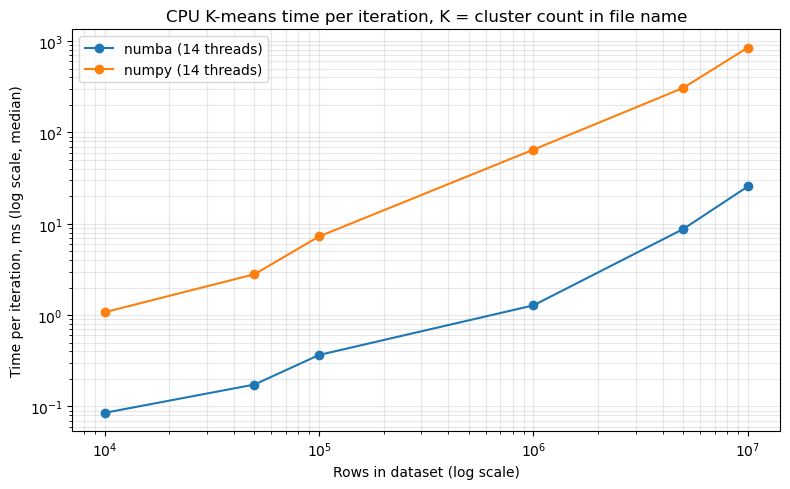

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
for impl, g in summary.groupby("implementation"):
    m = g.groupby("rows")["per_iter_ms_median"].median()
    ax.plot(m.index, m.values, marker="o", label=f"{impl} ({g['threads'].iloc[0]} threads)")
if comparison is not None:
    same = comparison[(comparison["K"] == comparison["K_original"]) & comparison["orig_per_iter_ms"].notna()]
    if len(same):   # the original runs used K = 17, so only same-K files are drawn
        m = same.drop_duplicates(["rows", "gen_clusters"]).groupby("rows")["orig_per_iter_ms"].median()
        ax.plot(m.index, m.values, marker="s", linestyle="--", color="grey", label="original run (same K only)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Rows in dataset (log scale)")
ax.set_ylabel("Time per iteration, ms (log scale, median)")
ax.set_title(f"CPU K-means time per iteration, K = {K_FIXED if K_MODE == 'fixed' else 'cluster count in file name'}")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "per_iteration_time.png", dpi=150)
plt.show()

## 8. Matching the GPU run to this baseline

Make the GPU code match these settings, or the comparison is not like for like:

* **Same inputs:** same data files with the same 9 feature columns (ID kept aside), the initial centroids from `results_cpu_optimized/initial_centroids_*.csv`, the same K, float32.
* **Same algorithm and stopping rule:** Lloyd's algorithm, with `TOL` and `MAX_ITER` as above, and max centroid movement (L2) as the stopping test.
* **Same timing protocol:** warm-up first, then the median over repeats of a fixed number of iterations. Synchronise the device before reading the clock (`torch.cuda.synchronize()` or `cp.cuda.Device().synchronize()`). Time host-to-device transfer separately.
* **Same correctness check:** run the GPU code for 1 and for 30 iterations with convergence off, from the same initial centroids, and compare its centroids with this notebook's. With float64 sums on both sides they should agree to about 1e-4. With float32 sums, assignments near ties can flip and the runs drift apart (section 5). Iteration counts to convergence can then differ, which is another reason to headline time per iteration.
* **Per-ID check:** join the GPU's per-ID clusters with `assignments/assignments_*.csv` on `ID` and report the share of IDs that land in the same cluster. Expect close to 100% from the same initial centroids, with the remaining differences in IDs whose distance to two centroids is almost equal.

Report two speedups: **GPU vs the original CPU code** and **GPU vs this optimised CPU baseline**. The second is the one to headline.